# 01 NLP概述、jieba分词与词向量入门


本篇对应课程 **day01**，放在「黑马程序员 → AI大模型开发 → 07-NLP自然语言处理」。课程视频目录按day01–day12安排，第1天的重点是：认识NLP、准备文本、jieba分词、NER/POS、one-hot，以及Word2Vec的CBOW原理。

资料：[2026最新版NLP自然语言处理](https://pan.baidu.com/s/16JhWSR5VZu0tEQ0EcRJBwA?pwd=1234)，提取码 `1234`。已核对 `03-视频/day01` 的 **16个视频标题**，并在线阅读《01-自然语言处理概念》12页及《02-文本预处理-上》中本篇相关的概念、分词、NER/POS、one-hot与CBOW内容（第1–35页），检查了CBOW原理页的图示。视频未逐段转录，课程代码目录和原始数据正文未取得。

本文依照资料的主题编写，示例语句、NumPy代码与5张图独立制作，不是教师代码的复刻。沿用前面笔记的格式：**全部为Markdown单元，Python代码块按顺序复制到代码单元即可运行；图片直接内嵌Notebook附件。**


## 本篇学习路线

| day01视频范围 | 学习内容 | 学完应能完成 |
| --- | --- | --- |
| 01–03 | 阶段大纲、发展简史、应用场景 | 区分理解、生成与具体NLP任务 |
| 04–05 | 文本预处理、沙箱和PyCharm | 建立独立环境，检查数据与标签 |
| 06–10 | jieba精确、全、搜索模式，繁体和词典 | 选择分词模式，修正领域词切分 |
| 11 | NER与POS | 区分实体边界和词性标签 |
| 12–15 | one-hot概念、获取、使用、实现 | 建词表、编码、处理未知词、保存映射 |
| 16 | Word2Vec与CBOW | 解释“上下文预测中心词”和词向量来源 |

从已有RNN笔记衔接：模型已经能接收token ID，但“怎样把真实文本变成稳定、可信的ID序列”同样关键。本篇先解决数据表示，再解释向量为何可以通过预测任务学出来。


## 1. NLP处理的是什么问题

**NLP（Natural Language Processing，自然语言处理）**研究如何让计算机处理、理解和生成人类语言，涉及计算机科学、人工智能与语言学。

- **NLU（自然语言理解）**：把语言转换为可用的结构或判断，例如意图分类、情感分析、实体抽取。
- **NLG（自然语言生成）**：根据输入生成语言，例如摘要、翻译、回答、写作。

| 应用 | 典型输入 → 输出 | 任务关注点 |
| --- | --- | --- |
| 情感分析 | 一条评论 → 正面/负面/中性 | 文本分类 |
| 信息抽取 | 一段新闻 → 人物、时间、机构等字段 | 实体与关系 |
| 搜索 | 查询 → 排序后的相关文档 | 召回、排序与语义匹配 |
| 问答 | 问题与上下文 → 答案 | 正确性、依据、表达 |
| 机器翻译 | 中文 → 英文等 | 内容保留与语言转换 |
| 自动摘要 | 长文 → 较短摘要 | 核心信息与事实一致性 |
| 语音助手 | 语音 → 识别文本 → 意图/回答 → 语音 | 语音和文本模块协作 |

语音识别和语音合成处理音频信号，常与文本NLP共同组成产品；不要把整个语音系统等同于一个文本分类模型。同一产品也可能同时用到NLP、计算机视觉、检索与业务规则。


## 2. 发展路线：规则、统计、表示学习与预训练

| 路线 | 核心方法 | 优势与局限 |
| --- | --- | --- |
| 规则方法 | 词典、语法、模板、人工规则 | 可解释，维护复杂，覆盖范围有限 |
| 统计方法 | 从语料估计概率，训练传统机器学习模型 | 能利用数据，特征设计仍重要 |
| 神经表示学习 | 词向量、RNN等学习特征 | 减少手工特征，依赖数据与训练 |
| 预训练与大模型 | 先用大语料学习，再适配任务 | 复用能力强，仍需可靠评价和数据处理 |

可以记住三个节点：1950年图灵讨论机器智能；2013年前后Word2Vec推动高效词向量学习；2017年Transformer提出，随后预训练语言模型广泛发展。它们是理解技术脉络的坐标，不意味着此前没有词向量或神经语言模型。

课件总结页出现了“2017年”与括号中“2013年Transformer”的年份冲突，本文统一采用 **2017年**。现代系统往往组合规则、检索和模型，技术发展并没有让数据分析与预处理失去作用。


## 3. 文本预处理：先理解数据，再决定怎么处理

预处理的目的，是组织模型需要的输入X和目标y，让数据的格式、类型、长度和标注符合任务要求。

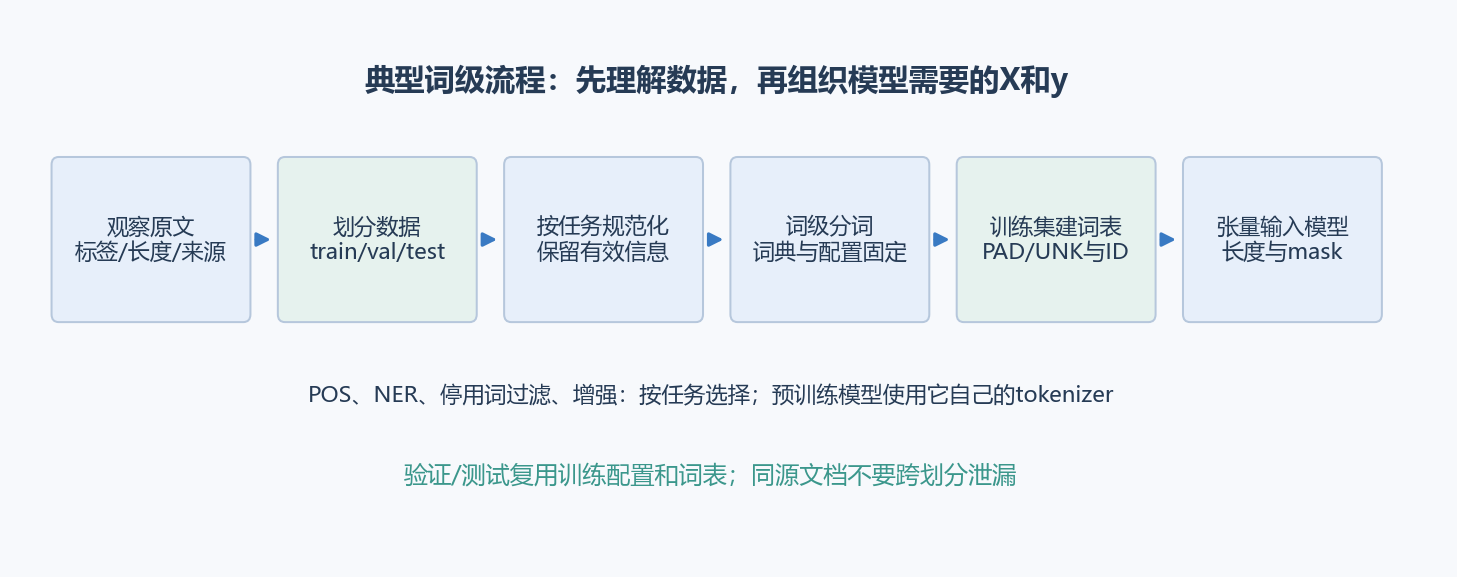

课件将预处理分为五个部分：文本基本处理、文本张量表示、语料分析、特征处理、数据增强。工程上通常先看数据：标签数和分布、句子长度、重复和空值、来源与标注规则，再决定采用哪些操作。

| 环节 | 可以检查/处理什么 | 需要注意 |
| --- | --- | --- |
| 语料分析 | 类别比例、长度、重复、缺失、来源 | 按人物、文档或时间划分，避免同源泄漏 |
| 文本规范化 | Unicode、空白、HTML、大小写 | 不要无条件删除否定词、数字、标点或符号 |
| 基本处理 | 分词、词性、命名实体 | 按任务选择，不是每个项目都必须执行 |
| 张量表示 | 词表ID、one-hot、稠密向量 | 映射与训练/推理必须一致 |
| 特征和长度 | n-gram、截断、填充、mask | 截断可能丢掉关键内容，PAD不能混进有效指标 |
| 增强 | 同义替换、回译等 | 增强可能改变标签；只在训练集上使用 |

停用词删除适用于部分统计或检索任务，不是统一标准。例如“我**不**喜欢”删掉“不”会改变情感；“C++”删掉符号会改变技术名称。直接使用预训练模型时，还应遵守它的tokenizer规范。


## 4. 建立独立环境，不把“沙箱”当作模型能力

视频包含“创建沙箱及关联PyCharm”。具体云平台操作未逐段核对，本篇给出可替代的**本地Python虚拟环境**流程；它帮助隔离依赖，不等同于对不可信代码提供安全隔离。

Windows终端中执行：

```powershell
python -m venv .venv-nlp
.\.venv-nlp\Scripts\python.exe -m pip install jieba==0.42.1 numpy
```

在PyCharm中选择该环境的解释器；在Jupyter中则确保内核使用安装了这些包的同一个Python。不要只在某个终端安装依赖，却在另一个解释器中运行代码。

```python
import io
import json
import re
import sys
import unicodedata
from collections import Counter
import numpy as np
import jieba
import jieba.posseg as pseg

print("Python:", sys.version.split()[0])
print("jieba:", jieba.__version__, "NumPy:", np.__version__)
tokenizer = jieba.Tokenizer()  # 独立实例，避免修改其他示例的全局词典
```

本篇NumPy示例不依赖TensorFlow、PyTorch或外部语料。首次使用jieba会初始化词典并可能建立缓存，后续调用通常更快。不同jieba版本、HMM设置和词典会影响结果，应记录配置。


## 5. 最小清洗：明确每条规则的作用

这里展示Unicode兼容规范化和空白整理，保留原始文本供追溯。NFKC可将某些全角字符转换为对应半角形式，也会改变部分兼容字符；应先确认是否符合业务要求。

```python
def normalize_text(text):
    if not isinstance(text, str):
        raise TypeError("输入必须是字符串")
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

raw_text = "  ＡＩ\t大模型\n我不喜欢删除关键信息。  "
clean_text = normalize_text(raw_text)
print("raw:", repr(raw_text))
print("clean:", clean_text)
assert clean_text == "AI 大模型 我不喜欢删除关键信息。"
assert "不" in clean_text and "。" in clean_text
assert normalize_text(clean_text) == clean_text
```

处理后字符位置可能改变。若要输出NER在原文中的坐标，需保留清洗前后的映射，或在保持原始坐标的文本上标注。中文繁简转换也不是NFKC的功能，不能把字符规范化当作繁体转简体。


## 6. 中文分词与tokenization

分词把连续字符序列按一定规则切成词序列。中文没有天然词间空格，存在边界歧义与未登录词；领域术语、人名、新产品名特别容易被切散。

tokenization是更宽泛的概念：token可以是词、字、子词或字节片段。jieba是中文词级分词工具；许多预训练模型使用自己的子词tokenizer，不需要先跑jieba。英文也不能只用空格解决所有tokenization问题，如标点、缩写、连字符和模型子词规则。

比较jieba的三种模式时，本篇固定`HMM=False`，减少未登录词识别带来的变化。jieba默认可以使用HMM处理新词，实际效果仍要按任务检查。


## 7. 精确模式：得到一条用于分析的切分路径

`cut_all=False`是默认精确模式。它试图选择一条合理的切分路径，适合多数词频统计和词级文本分析。

```python
sentence = "我来到北京清华大学"
cut_generator = tokenizer.cut(sentence, cut_all=False, HMM=False)
precise_tokens = list(cut_generator)
precise_again = tokenizer.lcut(sentence, cut_all=False, HMM=False)
print("precise:", precise_tokens)
assert precise_tokens == ["我", "来到", "北京", "清华大学"]
assert precise_tokens == precise_again
assert list(cut_generator) == []  # 生成器已被消费
assert "".join(precise_tokens) == sentence
```

`cut()`返回生成器，打印生成器对象并不会直接显示词列表。`list(...)`或`lcut()`得到列表；同一个生成器被遍历完后，不会自动回到开头。

“精确模式”是API名称，不代表切分永远准确。若任务需要把“清华大学”识别为机构名称，分词只是基础，不能代替实体识别。


## 8. 全模式：列出更多候选，不是一条不重叠路径

```python
full_tokens = tokenizer.lcut(sentence, cut_all=True, HMM=False)
print("full:", full_tokens)
assert {"清华", "华大", "大学", "清华大学"}.issubset(full_tokens)
```

本例中“清华大学”同时产生长词和子词候选。全模式不能消除歧义，候选可能相互重叠，因此不能直接拼接回原文，也不适合不加区分地当作一条普通词序列输入模型。

全模式扫描的是词典支持的候选，不是枚举所有可能的汉字子串。“清华大学”里出现“华大”也提醒我们：出现候选不等于它在当前语境里就是正确的词。


## 9. 搜索模式：保留长词，增加可检索的子词

搜索模式在精确切分的基础上补充部分长词的子词，帮助查询匹配更多文档；仍需要搜索系统的索引与排序策略，不会单独完成检索。

```python
search_tokens = tokenizer.lcut_for_search(sentence, HMM=False)
search_spans = list(tokenizer.tokenize(sentence, mode="search", HMM=False))
print("search:", search_tokens)
print("search spans:", search_spans)
assert "清华大学" in search_tokens and "大学" in search_tokens
assert all(sentence[start:end] == word for word, start, end in search_spans)
```

`tokenize()`返回`(词,开始位置,结束位置)`，坐标使用Python字符串字符索引，区间为 **[start,end)**。它们不是UTF-8字节偏移。搜索模式的区间可能重叠，例如“大学”和“清华大学”。

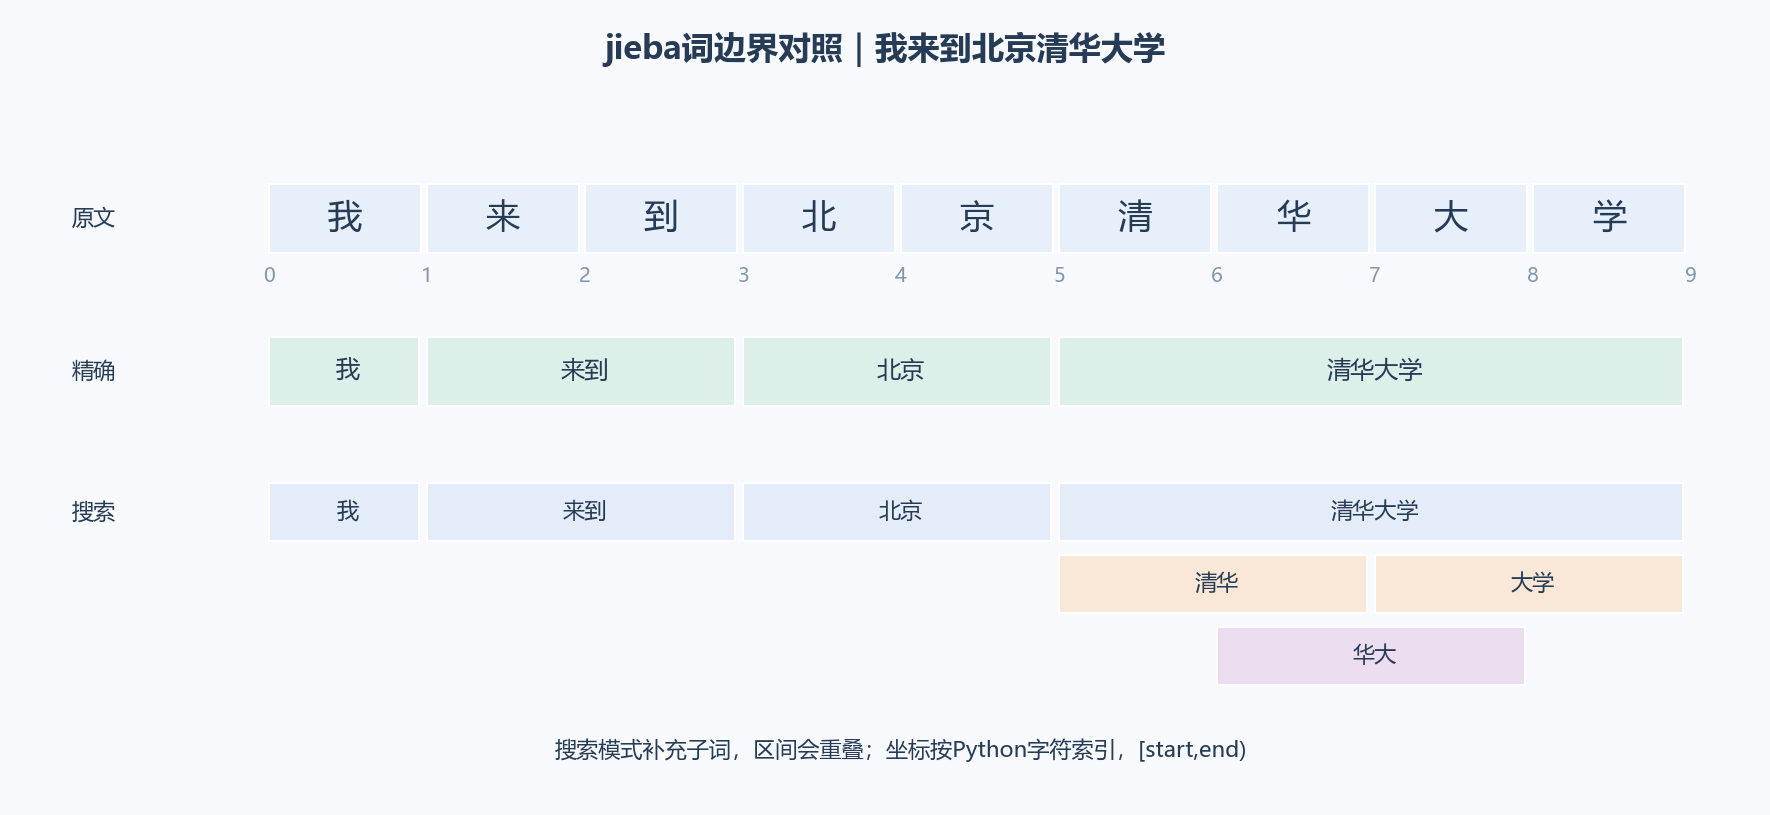

| 模式 | 切分特点 | 常见用途 |
| --- | --- | --- |
| 精确 | 选择一条切分路径 | 常规文本分析、词级序列 |
| 全 | 扫描更多词典候选 | 候选探索，需要进一步筛选 |
| 搜索 | 精确结果加长词子词 | 搜索索引与召回 |

不要把搜索模式生成的重叠词数当成原文自然词数，也不要由词更多就判断模型一定更好。


## 10. 繁体文本：能接收，不代表默认词典效果一致

jieba可以处理繁体字符串，但结果受词典覆盖与新词识别影响。简体默认词典可能把繁体词切成单字，需要合适的繁体词典或领域词典。

```python
traditional_text = "我們來到臺北學習自然語言處理"
traditional_before = tokenizer.lcut(traditional_text, HMM=False)
traditional_tokenizer = jieba.Tokenizer()
traditional_tokenizer.load_userdict(io.StringIO(
    "我們 100000 r\n臺北 100000 ns\n學習 100000 v\n"
    "自然語言處理 100000 nz\n"
))
traditional_after = traditional_tokenizer.lcut(traditional_text, HMM=False)
print("default dictionary:", traditional_before)
print("with example dictionary:", traditional_after)
assert "臺北" in traditional_after
assert "自然語言處理" in traditional_after
assert "".join(traditional_after) == traditional_text
```

这里只为演示增加了几条词，不代表完整的繁体语言资源。繁简转换会改变用词和字符形式，应保留原文并评估是否适合地区与任务；需要实体位置时还要考虑坐标对齐。


## 11. 自定义词典：把领域词作为整体

用户词典每行格式为`词语 [词频] [词性]`，按jieba规范用空格分隔；读取本地文件时通常用UTF-8。词频和词性可以省略，但必须符合库的解析格式。

```python
domain_tokenizer = jieba.Tokenizer()
domain_sentence = "我们正在学习大模型应用开发并使用向量数据库"
domain_before = domain_tokenizer.lcut(domain_sentence, HMM=False)
domain_dictionary = "大模型应用开发 100000 nz\n向量数据库 100000 nz\n"
domain_tokenizer.load_userdict(io.StringIO(domain_dictionary))
domain_after = domain_tokenizer.lcut(domain_sentence, HMM=False)
print("before:", domain_before)
print("after:", domain_after)
assert "大模型应用开发" in domain_after
assert "向量数据库" in domain_after
assert "".join(domain_after) == domain_sentence
```

使用内存文本流，例子不需要额外词典文件。示例的较高词频用于让效果容易观察，不是生产词频建议。词频会影响切分路径，盲目给每个术语极高词频可能误合并文本，应回归检查代表性句子。

`add_word()`、`del_word()`也可调整词典。训练和推理应加载同一版本词典；词典变化会进一步影响词表、ID和模型输入。


## 12. POS：给词标注语法类别

**POS（Part-Of-Speech tagging，词性标注）**为每个词标注词性，例如名词、动词、形容词或地名词等。

```python
pos_tokenizer = pseg.POSTokenizer(tokenizer)
pos_pairs = [(pair.word, pair.flag)
             for pair in pos_tokenizer.cut("我爱北京天安门", HMM=False)]
print("POS:", pos_pairs)
assert "".join(word for word, flag in pos_pairs) == "我爱北京天安门"
assert all(isinstance(flag, str) and flag for word, flag in pos_pairs)
```

| 常见jieba词性标签 | 含义 |
| --- | --- |
| n / v / a | 名词 / 动词 / 形容词 |
| r / d / m | 代词 / 副词 / 数词 |
| nr / ns / nt | 人名 / 地名 / 机构团体名 |
| nz / x | 其他专名 / 非语素词等 |

标签来自工具的标注体系，不能与其他工具的标签直接互换。jieba的词性是模型/词典判断，不是真实标注保证；检查结果比背标签更重要。


## 13. NER：识别实体跨度和实体类型

**NER（Named Entity Recognition，命名实体识别）**从文本中找出人名、地名、机构等实体，并确定对应的跨度。具体还可以识别日期、金额、产品等，取决于标注规范。

下面是**人工标注示例**，不是jieba自动NER结果：

```python
entity_text = "张三在北京加入清华大学。"
gold_entities = [
    {"text": "张三", "start": 0, "end": 2, "type": "PERSON"},
    {"text": "北京", "start": 3, "end": 5, "type": "LOCATION"},
    {"text": "清华大学", "start": 7, "end": 11, "type": "ORGANIZATION"},
]
for entity in gold_entities:
    assert entity_text[entity["start"]:entity["end"]] == entity["text"]
    print(entity)
```

POS回答“这个词是什么词性”，NER回答“哪一段文字是什么实体”。同一个实体可以覆盖多个分词结果，词性`ns/nr/nt`也不能代替可靠的NER边界与类型判断。

序列标注常用BIO：B是实体开始，I是实体内部，O是非实体。但分词或字符粒度、嵌套实体和类型范围必须先由标注规范确定。完整NER模型训练与评价不属于本篇day01示例。


## 14. 建词表：固定ID顺序，定义未知词

模型不能直接把汉字当作神经网络数值输入。本篇先分词，再从**训练文本**统计词表。预留`<PAD>`与`<UNK>`，排序后建立可重复的映射。

```python
training_texts = [
    "我爱自然语言处理", "我学习人工智能", "自然语言处理使用词向量"
]
training_tokens = [tokenizer.lcut(text, HMM=False) for text in training_texts]
training_counter = Counter(word for row in training_tokens for word in row)
itos = ["<PAD>", "<UNK>"] + sorted(training_counter)
stoi = {word: i for i, word in enumerate(itos)}
PAD, UNK = 0, 1
V = len(itos)

def encode_tokens(tokens):
    return np.array([stoi.get(word, UNK) for word in tokens], dtype=np.int64)

def decode_token_ids(ids):
    return [itos[int(i)] for i in ids]

demo_tokens = ["我", "学习", "人工智能", "词表之外"]
demo_ids = encode_tokens(demo_tokens)
print("training tokens:", training_tokens)
print("vocabulary:", itos)
print("IDs:", demo_ids, "decoded:", decode_token_ids(demo_ids))
assert demo_ids[-1] == UNK
assert len(itos) == len(stoi) == V
assert all(stoi[word] == i for i, word in enumerate(itos))
```

ID是索引，没有大小语义。`set`不提供可依赖的稳定迭代顺序，因此这里用`sorted`。训练/验证/测试中如果需要学习词表、词频过滤或归一化统计，应只在训练集拟合；预训练模型则沿用其已固定的词表。

不同教程可能从1开始编号，本篇从0开始，保留PAD=0。不要无条件套用`id-1`，否则PAD可能变成-1，并意外索引最后一列。


## 15. one-hot：指定位置为1，其余为0

词表大小为V，一个token的one-hot向量长V。ID为i，就令第i个位置为1。序列长度T时，词级one-hot矩阵为`(T,V)`，每行对应一个token。

```python
def one_hot_ids(ids, num_classes):
    ids = np.asarray(ids)
    if not np.issubdtype(ids.dtype, np.integer):
        raise TypeError("IDs必须是整数")
    if num_classes <= 0 or (ids.size and (ids.min() < 0 or ids.max() >= num_classes)):
        raise ValueError("ID超出词表范围")
    flat = ids.reshape(-1)
    encoded = np.zeros((len(flat), num_classes), dtype=np.float32)
    encoded[np.arange(len(flat)), flat] = 1.0
    return encoded.reshape(*ids.shape, num_classes)

demo_one_hot = one_hot_ids(demo_ids, V)
print("IDs shape:", demo_ids.shape, "one-hot shape:", demo_one_hot.shape)
print(demo_one_hot)
assert demo_one_hot.shape == (4, V)
assert np.all(demo_one_hot.sum(axis=1) == 1)
assert np.array_equal(demo_one_hot.argmax(axis=1), demo_ids)
assert np.array_equal(one_hot_ids(np.array([2, 2]), V)[0],
                      one_hot_ids(np.array([2, 2]), V)[1])
```

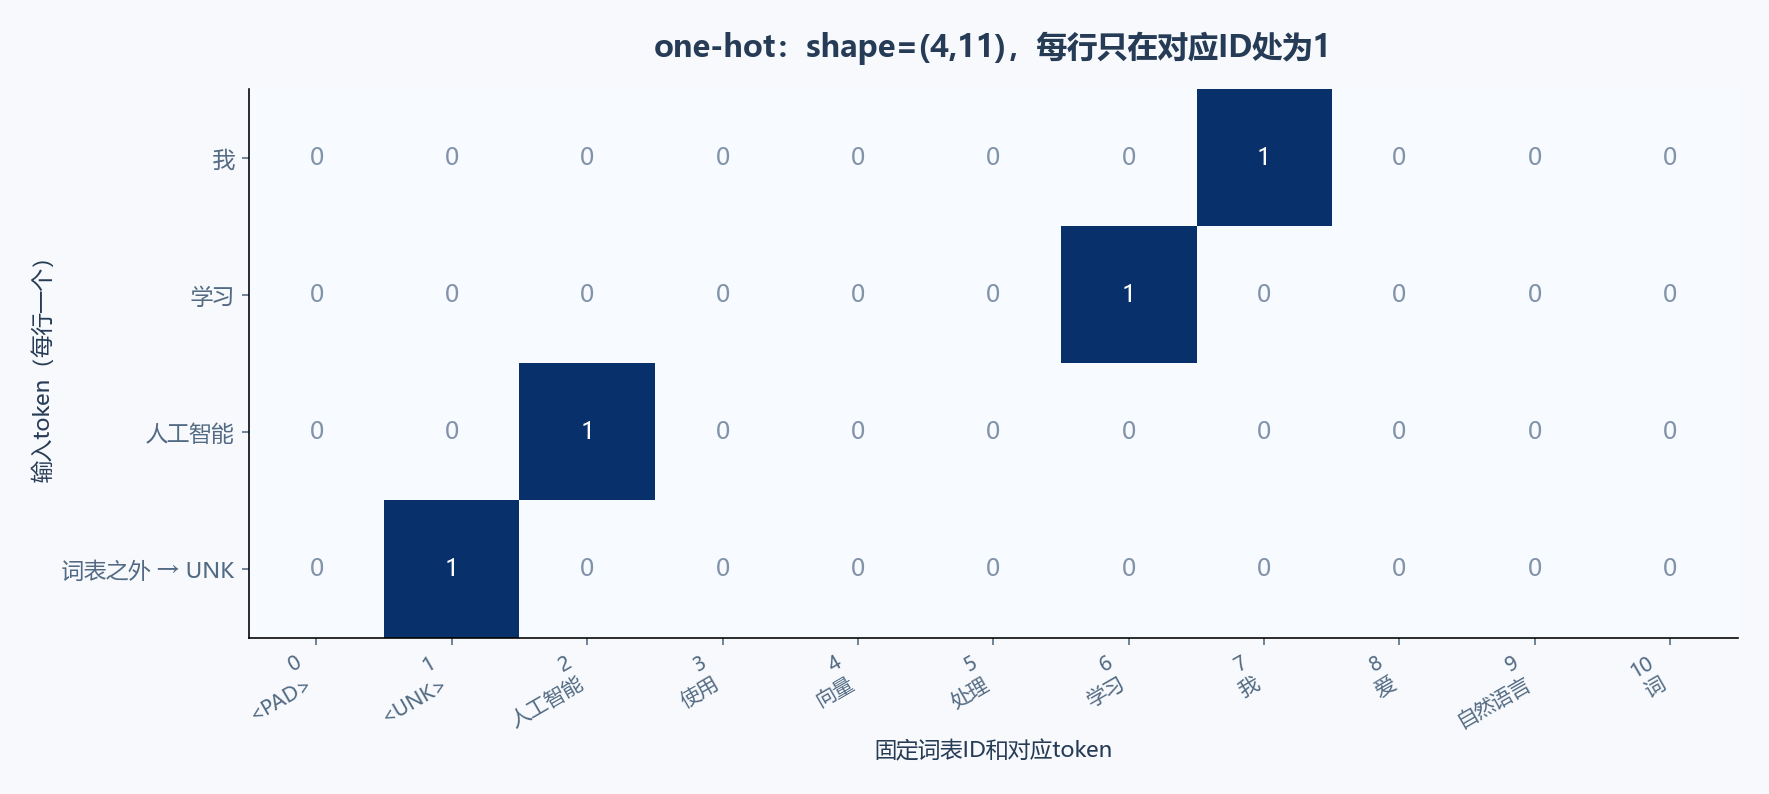

UNK是一个真实保留列，代表词表外词；本函数对PAD也返回含一个1的向量。**PAD不是天然零向量**，需要在具体模型与损失中明确处理。每个token的one-hot也不等于把整篇文档变成一个词频向量：后者通常聚合了词序。


## 16. one-hot的距离与内存限制

不同one-hot词向量彼此正交：点积为0、余弦相似度为0，欧氏距离均为$\sqrt{2}$。它们没有编码“北京”和“上海”比“北京”和“吃饭”更相关这样的信息。

```python
a_hot = one_hot_ids(np.array([stoi["我"]]), V)[0]
b_hot = one_hot_ids(np.array([stoi["学习"]]), V)[0]
assert np.dot(a_hot, b_hot) == 0.0
assert np.isclose(np.linalg.norm(a_hot - b_hot), np.sqrt(2))

batch_size, length, vocab_size = 32, 128, 50000
dense_onehot_bytes = batch_size * length * vocab_size * 4  # float32
id_bytes = batch_size * length * 8  # int64
print("one-hot MiB:", round(dense_onehot_bytes / 1024**2, 2))
print("IDs MiB:", round(id_bytes / 1024**2, 5))
```

该batch稠密one-hot约781.25 MiB，ID数组约0.03125 MiB，尚未计入梯度和其他模型内存。稀疏表示可减少存储，但实践中神经模型通常直接传ID，再用Embedding查表，不必先显式构造one-hot。

本函数直接建立所需输出大小；不要为了编码几个词先创建`np.eye(V)`，它会额外建立V×V的巨大单位矩阵。


## 17. 保存映射：编码规则必须跟模型一起保存

本例用JSON字符串演示保存和恢复，避免附加文件。实际写文件时可保存同样的对象，同时记录分词器版本、词典版本和清洗规则。

```python
vocabulary_state = {
    "itos": itos,
    "special_ids": {"pad": PAD, "unk": UNK},
    "jieba_version": jieba.__version__,
    "segmentation": {"mode": "precise", "HMM": False,
                     "dictionary": "jieba default dictionary"},
    "normalization": "none for the three training_texts",
}
saved_vocabulary = json.dumps(vocabulary_state, ensure_ascii=False)
loaded_vocabulary = json.loads(saved_vocabulary)
loaded_itos = loaded_vocabulary["itos"]
loaded_stoi = {word: i for i, word in enumerate(loaded_itos)}
reloaded_ids = np.array([
    loaded_stoi.get(word, loaded_vocabulary["special_ids"]["unk"])
    for word in demo_tokens
], dtype=np.int64)
assert np.array_equal(reloaded_ids, demo_ids)
assert loaded_itos == itos
print("vocabulary roundtrip passed")
```

不能加载旧权重后重新给词排序。即使词表大小相同，行顺序不同也会让ID查到错误向量。自定义词典内容和分词规则发生变化时，同一句话可能产生不同token，需要完整版本管理。

课件用Keras Tokenizer与joblib展示映射器的获取和使用；本文用NumPy和JSON独立实现同一编码原则，减少额外框架依赖。它不复现Keras的过滤、排序、OOV等全部默认行为。


## 18. 稠密向量：one-hot乘权重等价于查表

设词表大小V、向量维度D，嵌入矩阵$E\in\mathbb{R}^{V\times D}$。第i个one-hot向量乘以E，只取出第i行：

$$e_iE=E[i]$$

```python
rng = np.random.default_rng(2026)
embedding_table = rng.normal(0, 0.1, size=(V, 6)).astype(np.float32)
vectors_from_hot = demo_one_hot @ embedding_table
vectors_from_ids = embedding_table[demo_ids]
assert vectors_from_ids.shape == (4, 6)
assert np.allclose(vectors_from_hot, vectors_from_ids)
print("vector shape:", vectors_from_ids.shape,
      "embedding parameters:", embedding_table.size)
```

稠密向量长度由D控制，通常远小于V。随机向量只是初始化，不天然具有可靠语义；通过合适任务与数据训练，相关词才可能获得有用的表示。Word2Vec是学习词嵌入的一种方法，不等于所有Embedding层。

静态Word2Vec通常给一个词一条固定向量，无法直接区分同一个词在不同上下文中的意义；上下文语言模型会根据当前上下文产生不同表示。向量相近也不等于同义，反义词因共现环境相似也可能接近。


## 19. Word2Vec：从文本构造预测任务

Word2Vec从未人工标注的文本中构造输入与目标，通过预测词来学习向量。这种方式通常称为**自监督学习**：任务有目标y，但目标由文本本身生成。

| 方式 | 输入 | 预测目标 |
| --- | --- | --- |
| CBOW（Continuous Bag of Words） | 中心词周围的上下文 | 中心词 |
| Skip-gram | 中心词 | 周围上下文词 |

day01最后一个视频讲CBOW原理。本文只展开CBOW，Skip-gram与FastText的完整训练留到后续相关主题。Word2Vec是浅层神经预测模型，词向量保存在网络权重中，并不要求先做人工情感或实体标注。

CBOW将上下文向量求和或平均。平均会使上下文顺序被忽略；同样的上下文词交换顺序，平均表示不变。因此CBOW不等于前一章RNN按顺序传递状态的生成模型。


## 20. CBOW样本：窗口半径和总长度要分清

这里使用自编、已手工分词的短句，窗口**半径为1**，即左右各取一个词，总窗口长度为3。为了例子固定shape，只保留左右都有词的中心位置，不跨句构造上下文。

```python
cbow_sentences = [
    ["我", "爱", "自然语言处理"],
    ["你", "爱", "人工智能"],
    ["我", "学习", "人工智能"],
    ["你", "学习", "自然语言处理"],
]
cbow_itos = sorted({word for row in cbow_sentences for word in row})
cbow_stoi = {word: i for i, word in enumerate(cbow_itos)}
cbow_V, cbow_D = len(cbow_itos), 4

def make_cbow_samples(sentences, radius):
    if radius < 1:
        raise ValueError("radius必须至少为1")
    contexts, targets = [], []
    for words in sentences:
        for center in range(radius, len(words) - radius):
            context = words[center-radius:center] + words[center+1:center+radius+1]
            contexts.append([cbow_stoi[word] for word in context])
            targets.append(cbow_stoi[words[center]])
    return (np.array(contexts, dtype=np.int64).reshape(-1, 2 * radius),
            np.array(targets, dtype=np.int64))

cbow_contexts, cbow_targets = make_cbow_samples(cbow_sentences, radius=1)
for context, target in zip(cbow_contexts, cbow_targets):
    print([cbow_itos[i] for i in context], "->", cbow_itos[int(target)])
assert cbow_contexts.shape == (4, 2)
assert cbow_targets.shape == (4,)
assert [cbow_itos[i] for i in cbow_contexts[0]] == ["我", "自然语言处理"]
assert cbow_itos[int(cbow_targets[0])] == "爱"
```

一些工具参数`window=5`表示最大左右距离，和“总窗口长度5”不是同一个含义，必须看API定义。本例里每句仅生成一个样本，四个样本用于演示计算，不用于评估语义泛化。


## 21. CBOW前向：查表、平均、输出logits

使用行向量约定：输入嵌入矩阵E为`(V,D)`，输出权重U为`(D,V)`。对K个上下文词，平均得到D维向量h，再产生V个logits并预测中心词：

$$h=\frac{1}{K}\sum_{j=1}^{K}E[c_j],\qquad z=hU+b$$

$$p_i=\frac{\exp(z_i)}{\sum_{k=1}^{V}\exp(z_k)},\qquad L=-\log p_{y}$$

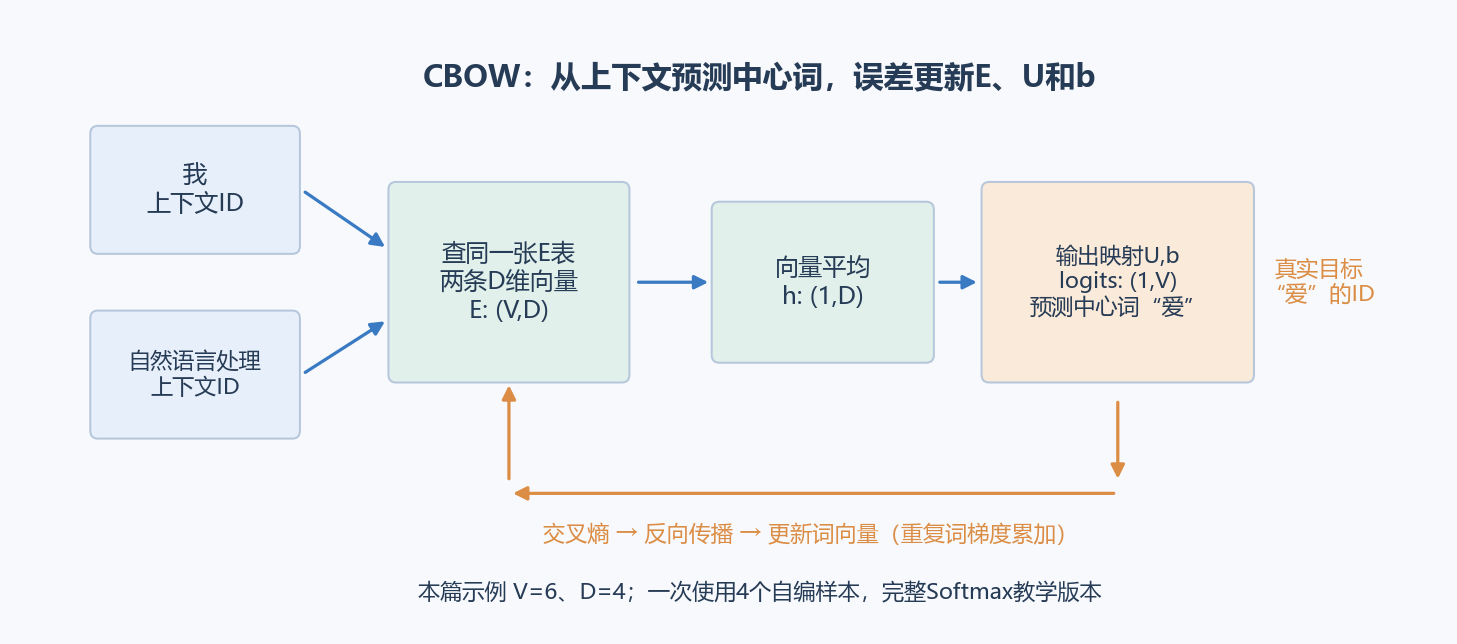

```python
cbow_rng = np.random.default_rng(2026)
cbow_E = cbow_rng.normal(0, 0.1, size=(cbow_V, cbow_D))
cbow_U = cbow_rng.normal(0, 0.1, size=(cbow_D, cbow_V))
cbow_b = np.zeros(cbow_V, dtype=np.float64)

def cbow_forward(context_ids, E, U, b):
    h = E[context_ids].mean(axis=1)
    logits = h @ U + b
    shifted = logits - logits.max(axis=1, keepdims=True)
    exp_scores = np.exp(shifted)
    probabilities = exp_scores / exp_scores.sum(axis=1, keepdims=True)
    return h, logits, probabilities

def cbow_loss(context_ids, targets, E, U, b):
    h, logits, probabilities = cbow_forward(context_ids, E, U, b)
    shifted = logits - logits.max(axis=1, keepdims=True)
    log_probabilities = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    loss = -log_probabilities[np.arange(len(targets)), targets].mean()
    return float(loss), h, probabilities

cbow_initial_loss, cbow_h, cbow_probs = cbow_loss(
    cbow_contexts, cbow_targets, cbow_E, cbow_U, cbow_b
)
print("h:", cbow_h.shape, "probabilities:", cbow_probs.shape,
      "loss:", round(cbow_initial_loss, 6))
assert cbow_h.shape == (4, cbow_D)
assert cbow_probs.shape == (4, cbow_V)
assert np.allclose(cbow_probs.sum(axis=1), 1)
_, _, reversed_probs = cbow_forward(cbow_contexts[:, ::-1], cbow_E, cbow_U, cbow_b)
assert np.allclose(reversed_probs, cbow_probs)
```

减去最大logit有助于数值稳定，不改变Softmax概率。课件使用列向量时写`(D,V)×(V,1)`，本文用行向量写`(1,V)×(V,D)`；本质是同一变换的转置约定，不能脱离约定背矩阵方向。

这里使用带偏置的完整Softmax教学版本，没有额外隐藏激活。真实大词表Word2Vec常用负采样或层次Softmax降低训练成本，本例不实现这些优化。


## 22. 一次反向更新：词向量怎样被训练

下面给出平均交叉熵的NumPy梯度，用一小步更新核对“预测误差会更新词向量”。这是原理演示，不是完整Word2Vec训练或语义质量评价。

```python
def cbow_loss_and_grads(context_ids, targets, E, U, b):
    loss, h, probabilities = cbow_loss(context_ids, targets, E, U, b)
    n, k = context_ids.shape
    dz = probabilities.copy()
    dz[np.arange(n), targets] -= 1.0
    dz /= n
    dU = h.T @ dz
    db = dz.sum(axis=0)
    dh = dz @ U.T
    dE = np.zeros_like(E)
    for position in range(k):
        np.add.at(dE, context_ids[:, position], dh / k)
    return loss, dE, dU, db

before_loss, grad_E, grad_U, grad_b = cbow_loss_and_grads(
    cbow_contexts, cbow_targets, cbow_E, cbow_U, cbow_b
)
learning_rate = 0.1
updated_E = cbow_E - learning_rate * grad_E
updated_U = cbow_U - learning_rate * grad_U
updated_b = cbow_b - learning_rate * grad_b
after_loss, after_h, after_probs = cbow_loss(
    cbow_contexts, cbow_targets, updated_E, updated_U, updated_b
)
print("one gradient step:", round(before_loss, 6), "->", round(after_loss, 6))
assert after_loss < before_loss
context_rows = set(cbow_contexts.reshape(-1).tolist())
assert all(np.allclose(grad_E[i], 0) for i in range(cbow_V) if i not in context_rows)
assert np.linalg.norm(updated_E - cbow_E) > 0
```

相同词可能在同一批次出现多次，应把它的梯度**累加到同一嵌入行**。`np.add.at`明确处理重复ID；直接用带重复索引的赋值更新，可能遗漏累加。

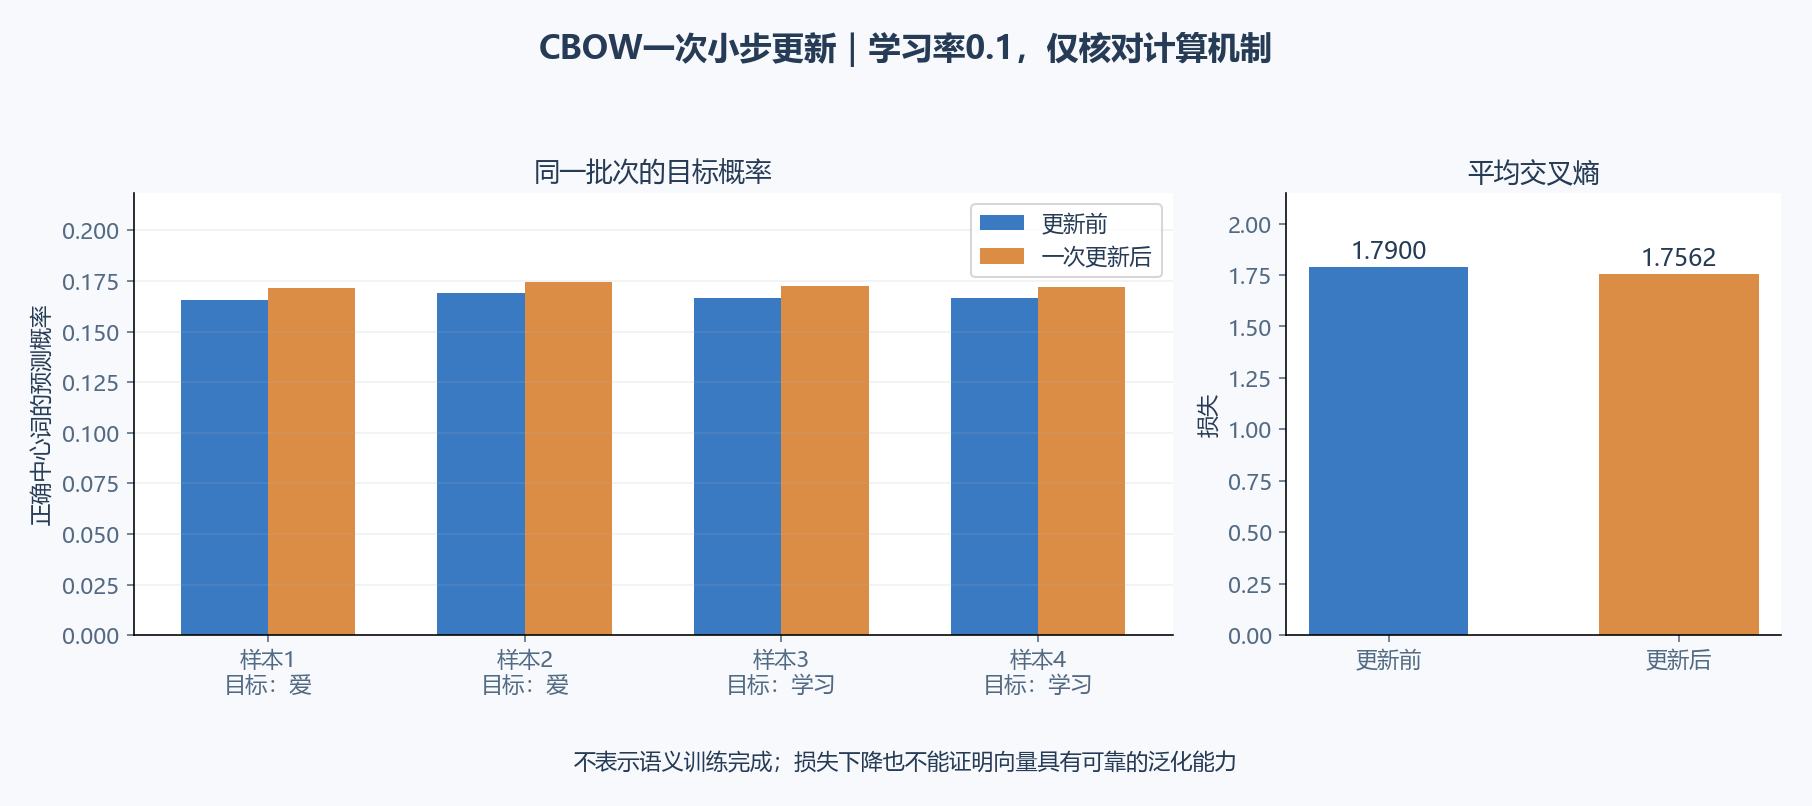

本次小步使平均训练损失下降，仅证明数据流和梯度更新起作用；不是每次任意学习率都保证损失下降，也不能证明学到了可靠的语义。大语料中要迭代处理大量窗口，再用相似词、下游任务等检查表示质量。


## 23. 读出词向量，区分参数与预测结果

```python
word_to_inspect = "人工智能"
word_vector = updated_E[cbow_stoi[word_to_inspect]].copy()
print(word_to_inspect, "vector shape:", word_vector.shape, "vector:", word_vector)
assert word_vector.shape == (cbow_D,)
assert np.allclose(
    one_hot_ids(np.array([cbow_stoi[word_to_inspect]]), cbow_V) @ updated_E,
    word_vector[None, :],
)
```

E的每一行对应一个词的输入向量；U也包含另一组输出侧参数。这里按课件原理读取E作为词向量。中心词的Softmax概率是当前上下文下的预测结果，不是这个词的固定嵌入。

只有输入嵌入矩阵E的行与词表ID配套，才知道每个向量属于哪个词。D维向量的某一列通常不能直接解释为“感情”“地点”这样的人工语义标签。四个样本和一次更新仍接近随机初始化，不适合展示“最相似词”或词向量类比结论。


## 24. 实跑观察记录

以下是本篇所有Python代码块在CPU上的实际结果。jieba版本为0.42.1，分词对比固定HMM=False；不同版本、词典或配置可能改变词边界。

| 核对项 | 实跑结果 |
| --- | --- |
| 精确模式 | 我 / 来到 / 北京 / 清华大学 |
| 全模式 | 我 / 来到 / 北京 / 清华 / 清华大学 / 华大 / 大学 |
| 搜索模式 | 我 / 来到 / 北京 / 清华 / 华大 / 大学 / 清华大学 |
| 领域词典 | “大模型应用开发”“向量数据库”均作为整体 |
| POS示例 | 我:r / 爱:v / 北京:ns / 天安门:ns |
| 训练例子词表大小 | 11（含PAD、UNK） |
| one-hot和稠密向量shape | `(4,11)` / `(4,6)` |
| CBOW样本、词表、向量维度 | 4个样本；V=6；D=4 |
| CBOW输出概率shape | `(4,6)` |
| CBOW一次更新前/后平均损失 | 1.790026 → 1.756233 |

已核对：精确切分可拼回原句，搜索跨度与原文对齐，人工实体坐标正确，未知词映射到UNK，one-hot和查表结果一致，词表保存后ID不变，CBOW上下文换序不改变平均表示，重复ID梯度正确累加。

NumPy反向梯度还与中心差分的数值梯度对照，最大绝对误差小于`1e-7`。这些验证说明本篇代码和张量计算一致，不代表训练出了成熟的词向量模型，也不构成下游任务成绩。


## 25. 常见错误与排查

| 问题 | 原因与排查方向 |
| --- | --- |
| 打印cut只看到generator | 用list()展开或使用lcut()；不要重复消费同一个生成器 |
| 多跑几次分词结果变了 | 自定义词典、全局实例、HMM或版本发生变化 |
| 领域词被切散 | 检查词典、词频、前后文和模式；增加有代表性的回归句子 |
| 繁体词切成单字 | 默认词典覆盖有限，需适合语种和领域的资源 |
| 搜索模式词太多且重叠 | 这是子词补充行为，不要当作精确模式路径 |
| 清洗后实体坐标对不上 | 空白整理、Unicode或繁简处理改变了字符位置 |
| 把nr/ns当成完备NER | POS是词性；NER还要实体边界、任务类型和标注规范 |
| 新文本查词表报KeyError | 设计UNK策略，或使用模型原有tokenizer |
| one-hot最后一列莫名被置1 | 检查id-1造成-1索引，确认0/1起始编号 |
| one-hot消耗内存过大 | 检查B×T×V，使用ID查表或适当稀疏表示 |
| 加载模型后预测变化 | 词表行序、清洗、词典、分词器配置与权重不一致 |
| CBOW矩阵无法相乘 | 区分V、D、K，确认使用行向量还是列向量约定 |
| CBOW重复词梯度不正确 | 更新同一嵌入行要累加，不要覆盖 |
| 随机向量看起来接近就认为学到了语义 | 需要充分训练及可靠验证；小例子只证明机制 |

看见不合理结果时，先核对原文→token→ID→张量每一步，再调整模型。分词后的错误不一定能通过增大网络修复。


## 26. 练习与参考答案

1. “我不喜欢这款产品”做情感分析时，能否无条件删除“不”？
2. 精确模式与搜索模式中，“清华大学”的处理有什么区别？
3. `cut()`和`lcut()`返回值有何区别？同一个生成器还能重复读取吗？
4. 词表大小5000，序列长度20，词级one-hot矩阵是什么shape？Embedding维度64时又是什么shape？
5. 不同词的one-hot余弦相似度是多少？这说明什么？
6. 分词、POS和NER分别回答什么问题？jieba词性标签能否保证实体识别正确？
7. 左右半径2的CBOW完整窗口包含几个词？输入上下文几个词，目标几个词？
8. 上下文词顺序交换后，本篇CBOW输出是否变化？它能直接用于按顺序生成句子吗？
9. 保存一个嵌入矩阵后，为什么还要保存词表？

参考答案：

- 第1题：不能；删除否定词可能反转情感标签。
- 第2题：精确模式通常保留“清华大学”整体；搜索模式额外产生“清华”“华大”“大学”等词典支持的子词候选。
- 第3题：cut返回生成器，lcut返回列表；被消费完的同一个生成器不会重置。
- 第4题：`(20,5000)`；稠密嵌入为`(20,64)`，序列顺序由行顺序保留。
- 第5题：0；不同词均正交，编码没有直接表达词义相似性。
- 第6题：分词决定词边界，POS标注词性，NER找实体跨度与类型；词性标签不保证NER正确。
- 第7题：完整窗口5个词，上下文4个词，中心目标1个词。
- 第8题：平均后的向量不变，输出不变；本例不是保持顺序与因果约束的自回归生成模型。
- 第9题：向量行与ID对应，没有稳定词表就不知道每一行属于哪个词。

实践建议：选10条领域短句，记录加入自定义词典前后的切分；统计训练文本长度与UNK比例；把CBOW上下文中同一词重复一次，核对梯度累加；随后再学习完整词向量训练。


## 27. 速查

| 概念/API | 关键点 |
| --- | --- |
| NLP / NLU / NLG | 自然语言处理 / 理解 / 生成 |
| jieba.cut、lcut | 生成器 / 列表，默认精确模式 |
| cut_all=True | 全模式扫描候选，可能重叠 |
| cut_for_search、lcut_for_search | 长词补充子词，适合检索索引 |
| tokenize | token与[start,end)字符坐标 |
| load_userdict | 词语 [词频] [词性]，注意词典版本 |
| jieba.posseg | 词性标注，不是通用NER模型 |
| NER | 实体跨度与类型；坐标、粒度按规范定义 |
| 词表 | train拟合，固定顺序，PAD/UNK明确 |
| one-hot | 每token V维，ID对应位置为1 |
| Embedding | ID查E的一行，E通常为(V,D) |
| CBOW | 多个上下文向量平均 → 中心词logits |
| Skip-gram | 中心词 → 上下文词 |
| 保存 | 权重、词表、词典、分词与清洗配置配套 |


## 28. day01资料对照与来源范围

已核对的视频文件名（省略共同的`.mp4`扩展名）：

| 序号 | 标题 |
| --- | --- |
| 01 | NLP阶段大纲介绍(理解) |
| 02 | NLP发展简史介绍(了解) |
| 03 | NLP应用场景介绍(了解) |
| 04 | 文本预处理的主要模块介绍(理解) |
| 05 | 如何创建沙箱及关联PyCharm(掌握) |
| 06 | jieba分词_精确模式介绍(掌握) |
| 07 | jieba分词_全模式介绍(理解) |
| 08 | jieba分词_搜索引擎模式介绍(掌握) |
| 09 | jieba分词_繁体字(理解) |
| 10 | jieba分词_用户自定义词典(理解) |
| 11 | 文本预处理_NER和POS解释(理解) |
| 12 | 文件张量表示法_one-hot编码介绍(理解) |
| 13 | one-hot编码_获取(理解) |
| 14 | one-hot编码_使用(理解) |
| 15 | one-hot编码_简单实现思路(掌握) |
| 16 | word2vec_CBOW原理介绍(理解) |

第12个标题中的“文件张量”按目录原文保留，正文对应的是文本张量表示。

本篇对照了分享中`01-课件/01-自然语言处理概念.pdf`（12页）与`02-文本预处理-上.pdf`的相关页：第4–6页预处理，第8–21页分词/NER/POS，第24–30页张量与one-hot，第31–35页Word2Vec与CBOW。采用网页预览读取正文，未取得本地PDF文件。第二份课件共64页，跨越后续词向量工具和Embedding等主题，本篇不将整个课件都算作day01。

**未核对范围：**视频未逐段转录；课程原代码与原语料正文、思维导图内容未取得。本文的本地虚拟环境、稳定词表、JSON保存、NumPy前后向和全部图示是独立教学补充。图示依据本文例子制作，不是教师课件截图。

可进一步查阅：

- [jieba官方项目与API说明](https://github.com/fxsjy/jieba)
- [Word2Vec原论文：Efficient Estimation of Word Representations in Vector Space](https://arxiv.org/abs/1301.3781)
- [Transformer原论文：Attention Is All You Need](https://arxiv.org/abs/1706.03762)
